# 09 - Support Vector Machine (SVM)

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Goal:** Train and evaluate the model on the processed PhiUSIIL data, compare different feature sets, and test the URL-only version on the external dataset.

**Input:** `data/processed/`

**Output:** `results/metrics/`, `results/confusion_matrices/`

## Setup

We load the libraries and the shared functions from `src/`. Every team member uses the same functions, so all results are calculated in the same way and can be compared fairly.

In [1]:
import sys
import time
from pathlib import Path

import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.svm import LinearSVC

sys.path.append(str(Path("..").resolve()))

from src.data import (
    get_feature_sets,
    load_train_test,
    sample_rows,
)

from src.evaluation import (
    RANDOM_STATE,
    cross_validate_model,
    evaluate_model,
    make_cv,
    make_scaled_pipeline,
    plot_confusion_matrix,
    save_results,
)

In [2]:
X_train, X_test, y_train, y_test = load_train_test()
feature_sets = get_feature_sets()

print(f"Training set: {X_train.shape[0]:,} rows | {X_train.shape[1]} features")
print(f"Test set:     {X_test.shape[0]:,} rows | {X_test.shape[1]} features")

Training set: 187,363 rows | 69 features
Test set:     46,841 rows | 69 features


## Model Settings

We choose the model, the settings we want to try during tuning, and the sample size for tuning.

In [3]:
MODEL_NAME = "SVM"

model = make_scaled_pipeline(
    LinearSVC(
        max_iter=5000,
        random_state=RANDOM_STATE
    )
)

param_grid = {
    "linearsvc__C": [0.01, 0.1, 1, 10],
}

TUNING_SAMPLE_SIZE = 30000

print("Model:", MODEL_NAME)
print("Tuning sample size:", TUNING_SAMPLE_SIZE)
print("Hyperparameters:", param_grid)

Model: SVM
Tuning sample size: 30000
Hyperparameters: {'linearsvc__C': [0.01, 0.1, 1, 10]}


## 1. Hyperparameter Tuning

We try each combination of settings in `param_grid` using 3-fold cross-validation on the training set, and keep the one with the best F1-score. The test set is not used here.

In [4]:
X_tune, y_tune = sample_rows(
    X_train,
    y_train,
    TUNING_SAMPLE_SIZE
)

search = GridSearchCV(
    model,
    param_grid,
    scoring="f1",
    cv=make_cv(3),
    n_jobs=-1
)

search.fit(X_tune, y_tune)

best_model = search.best_estimator_

print(f"Best settings: {search.best_params_}")
print(f"Best cross-validation F1: {search.best_score_:.4f}")

Best settings: {'linearsvc__C': 0.1}
Best cross-validation F1: 0.9999


## 2. Cross-Validation

We check the best model with 5-fold stratified cross-validation. The mean shows the usual score, and the standard deviation (Std) shows how stable the model is. A small Std means the model gives similar results on different parts of the data.

In [5]:
cv_results = cross_validate_model(best_model, X_tune, y_tune)
cv_results.round(4)

,Mean,Std
Accuracy,0.9999,0.0001
Precision,1.0000,0.0000
Recall,0.9998,0.0002
F1,0.9999,0.0001
ROC-AUC,1.0000,0.0000


### Learning Curve

A learning curve shows how the score changes when the model gets more training data. We use the best settings from tuning and 5-fold cross-validation on a sample of 50,000 training rows.

- **Training F1:** the score on the data the model was trained on.
- **Validation F1:** the score on data the model did not see.

How we read it (at the last point):

- **Overfitting:** the gap (training F1 − validation F1) is more than 0.01. The model memorises the training data.
- **Underfitting:** validation F1 is below 0.95 and the gap is small. The model is too simple to learn the pattern.
- **Good fit:** both lines are high and close together.

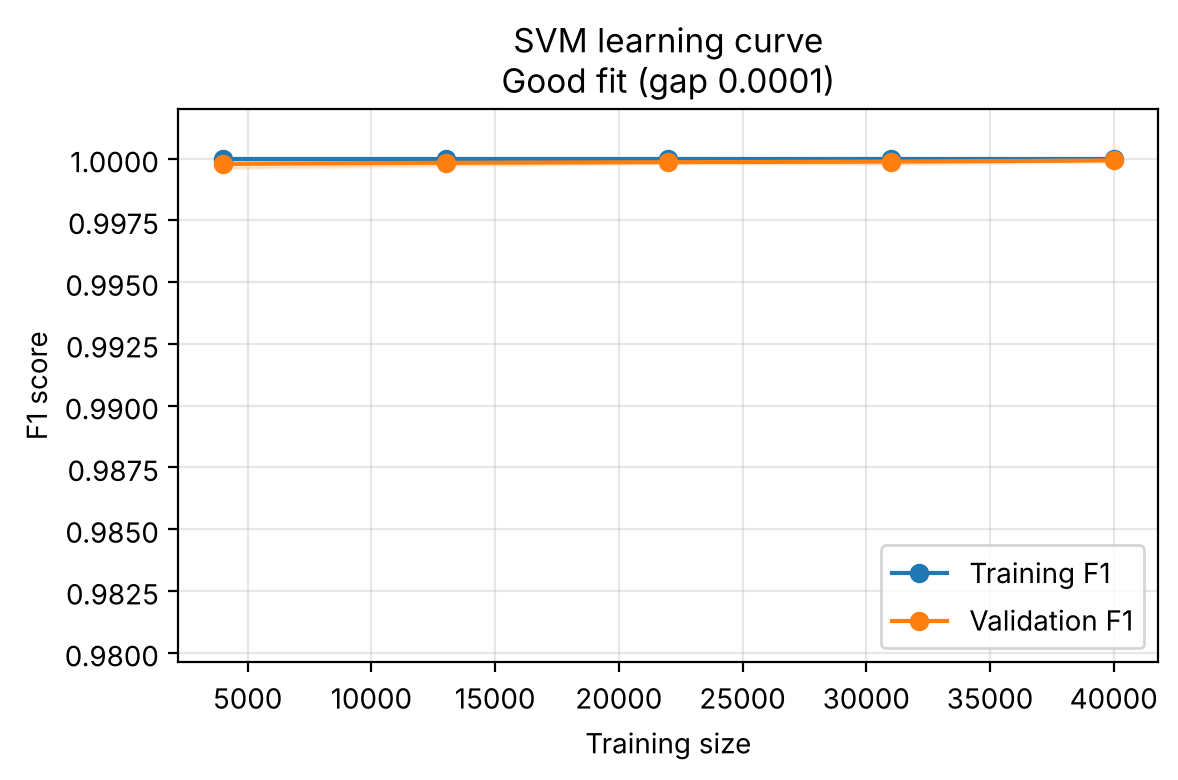

Result: Good fit (gap 0.0001)


,Training size,Training F1,Training Std,Validation F1,Validation Std
0,4000,1.0,0.0,0.9998,0.0002
1,13000,1.0,0.0,0.9998,0.0001
2,22000,1.0,0.0,0.9999,0.0000
3,31000,1.0,0.0,0.9999,0.0001
4,40000,1.0,0.0,0.9999,0.0001


In [ ]:
from src.evaluation import describe_fit, learning_curve_table, plot_learning_curve

X_curve, y_curve = sample_rows(X_train, y_train, 50000)
curve = learning_curve_table(best_model, X_curve, y_curve)
plot_learning_curve(curve, f"{MODEL_NAME} learning curve")

fit, gap = describe_fit(curve)
print(f"Result: {fit} (gap {gap:.4f})")
curve.round(4)

**Result: Good fit.**

- Training F1 is 1.0000 and validation F1 is 0.9999 at the last point, so the gap is only 0.0001.
- The validation F1 goes up a little as we add more data.
- So the linear SVM is not overfitting. The small C = 0.1 keeps the model simple.

## 3. Final Test

We train the best model on the full training set and test it once on the test set. This is the score we report for this model.

In [6]:
start = time.perf_counter()
final_model = clone(best_model).fit(X_train, y_train)
train_time = time.perf_counter() - start

test_results = evaluate_model(final_model, X_test, y_test)
print(f"Training time: {train_time:.1f} seconds")
pd.Series(test_results).round(4).to_frame("Test Score")

Training time: 1.5 seconds


,Test Score
Accuracy,1.0000
Precision,1.0000
Recall,0.9999
F1,0.9999
ROC-AUC,1.0000


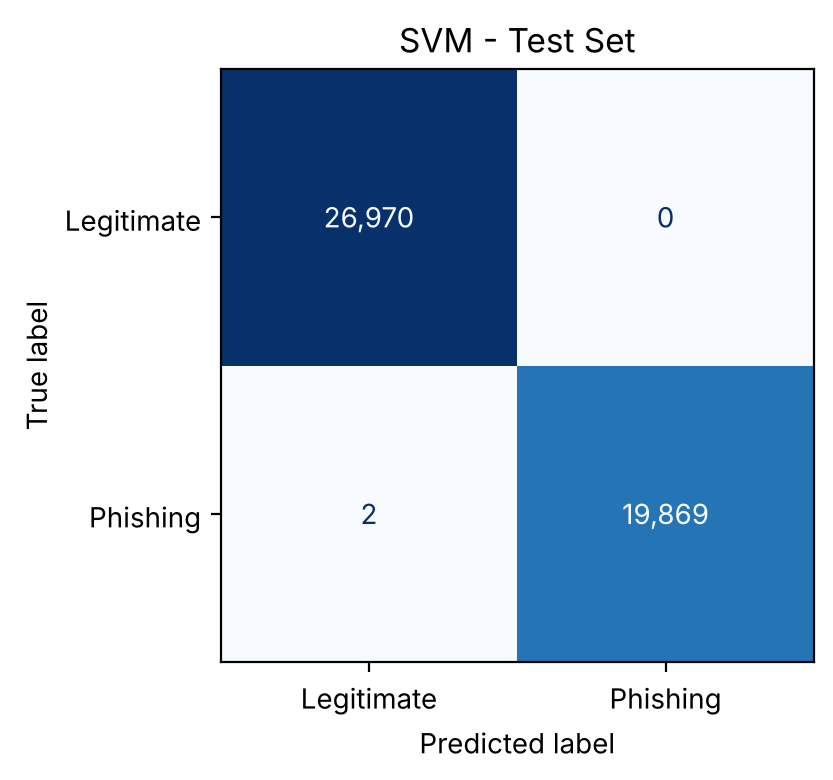

In [7]:
plot_confusion_matrix(y_test, final_model.predict(X_test), f"{MODEL_NAME} - Test Set")

## 4. Feature Set Comparison

We train the same model on two smaller feature sets to answer two questions:

- **Original features only:** do our new features from feature engineering improve the model?
- **Without `URLSimilarityIndex`:** does the model still work well without its strongest feature?

In [8]:
feature_results = {}

for feature_name, columns in feature_sets.items():
    if feature_name == "All features":
        continue

    comparison_model = clone(best_model)
    comparison_model.fit(X_train[columns], y_train)

    feature_results[feature_name] = evaluate_model(
        comparison_model,
        X_test[columns],
        y_test
    )

pd.DataFrame(feature_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
Original features only,1.0,1.0,0.9999,0.9999,1.0
Without URLSimilarityIndex,1.0,1.0,0.9999,0.9999,1.0


## 5. Save the Results

We save all results in one table. The comparison notebook will later load the tables of all models.

In [9]:
results = [
    {"Experiment": "Cross-validation", **cv_results["Mean"].to_dict()},
    {"Experiment": "Test set - All features", **test_results, "Train Time (s)": train_time},
    {"Experiment": "Test set - Original features only", **feature_results["Original features only"]},
    {"Experiment": "Test set - Without URLSimilarityIndex", **feature_results["Without URLSimilarityIndex"]},
]

save_results(MODEL_NAME, results).round(4)

,Model,Experiment,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time (s)
0,SVM,Cross-validation,0.9999,1.0,0.9998,0.9999,1.0,NaN
1,SVM,Test set - All features,1.0000,1.0,0.9999,0.9999,1.0,1.505
2,SVM,Test set - Original features only,1.0000,1.0,0.9999,0.9999,1.0,NaN
3,SVM,Test set - Without URLSimilarityIndex,1.0000,1.0,0.9999,0.9999,1.0,NaN


## 6. Findings


- The Linear Support Vector Machine (SVM) achieved excellent performance on the PhiUSIIL dataset.
- The best hyperparameter was `C = 0.1`, selected using GridSearchCV on a sample of 30,000 training URLs.
- Cross-validation achieved a mean accuracy of 99.99% and a mean F1-score of 99.99%.
- The final model achieved 99.996% accuracy on the internal test set, with only two phishing URLs incorrectly classified as legitimate and no false alarms.
- Using only original features or removing `URLSimilarityIndex` gave exactly the same result (2 mistakes), so the model does not depend on a single feature.

### Conclusion

The SVM model demonstrates excellent classification performance on the PhiUSIIL dataset. It is fast to train (about 1.5 seconds) and stable across all feature sets.